**UTS PEMBELAJARAN MESIN - 
| NAMA : NATAN VALESKA PAPUTUNGAN |
| NIM  : 202431137 |**

In [1]:
# NIM: 202431137 - Natan Valeska Paputungan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Pustaka berhasil dimuat untuk NIM: 202431137")

Pustaka berhasil dimuat untuk NIM: 202431137


In [2]:
# NIM: 202431137 - Natan Valeska Paputungan
df = pd.read_csv('02_diabetes.csv')
print("Dimensi Dataset Diabetes:", df.shape)
display(df.head())
print(df.info())

Dimensi Dataset Diabetes: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB
None


In [3]:
# NIM: 202431137 - Natan Valeska Paputungan
# Mengonversi kolom kategorikal menjadi representasi numerik
cat_cols = ['gender', 'smoking_history']
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

X = df.drop(columns=['diabetes'])
y = df['diabetes']

# Membagi data latih dan data uji dengan rasio 80:20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Melakukan normalisasi skala fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Pra-pemrosesan data berhasil diselesaikan untuk NIM: 202431137")

Pra-pemrosesan data berhasil diselesaikan untuk NIM: 202431137


In [4]:
# NIM: 202431137 - Natan Valeska Paputungan
# 1. Model Regresi Linear
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
y_pred_lin = lin_reg.predict(X_test_scaled)
y_pred_lin_binary = [1 if val >= 0.5 else 0 for val in y_pred_lin]
acc_lin = accuracy_score(y_test, y_pred_lin_binary)

# 2. Model Klasifikasi K-Nearest Neighbors (KNN)
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)
acc_knn = accuracy_score(y_test, y_pred_knn)

print(f"Tingkat Akurasi Regresi Linear (Thresholded): {acc_lin:.4f}")
print(f"Tingkat Akurasi KNN (k=5): {acc_knn:.4f}")

Tingkat Akurasi Regresi Linear (Thresholded): 0.9385
Tingkat Akurasi KNN (k=5): 0.9613


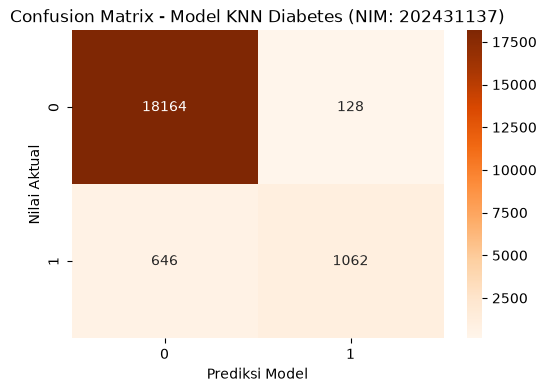

Laporan Klasifikasi Model KNN:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98     18292
           1       0.89      0.62      0.73      1708

    accuracy                           0.96     20000
   macro avg       0.93      0.81      0.86     20000
weighted avg       0.96      0.96      0.96     20000



In [5]:
# NIM: 202431137 - Natan Valeska Paputungan
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Oranges')
plt.title('Confusion Matrix - Model KNN Diabetes (NIM: 202431137)')
plt.xlabel('Prediksi Model')
plt.ylabel('Nilai Aktual')
plt.show()

print("Laporan Klasifikasi Model KNN:\n", classification_report(y_test, y_pred_knn))